# Deutsch-Algorithm — IQM edition

This notebook runs on **IQM** quantum computers — **Garnet** (20 qubits) or **Emerald** (54 qubits) — via **IQM Resonance**.

IQM chips use the native gate set **PRX (phased-RX) + CZ**. The helper `run_counts` transpiles each circuit to these native gates before running, so the circuit-construction code below stays unchanged.

**Pick your backend by editing the single `TARGET` line in the next cell.** Options:

- `"fake_apollo"` — local 20-qubit noisy simulator, **no token** needed (default, fully offline).
- `"garnet:mock"` / `"emerald:mock"` — IQM Resonance **cloud mock** (needs a token, **no QPU time**). It validates the job pipeline (token, transpilation, connectivity, instruction limit) but returns **random bitstrings**, not simulated physics: verify logic with `fake_apollo`.
- `"garnet"` / `"emerald"` — the **real QPU** (needs a token **and** QPU credits).

See `README.md` in this folder for setup and token instructions.

In [ ]:
from iqm_backend import get_backend, run_counts   # helper module in this folder (see iqm_backend.py)
# run_counts(circuit, TARGET, shots=...) = transpile to the IQM native gates (PRX + CZ) + run + get_counts()
# get_backend(TARGET) returns the raw Qiskit backend object if you want to call backend.run yourself
TARGET = "fake_apollo"   # change this one line to choose the backend (see the table above)


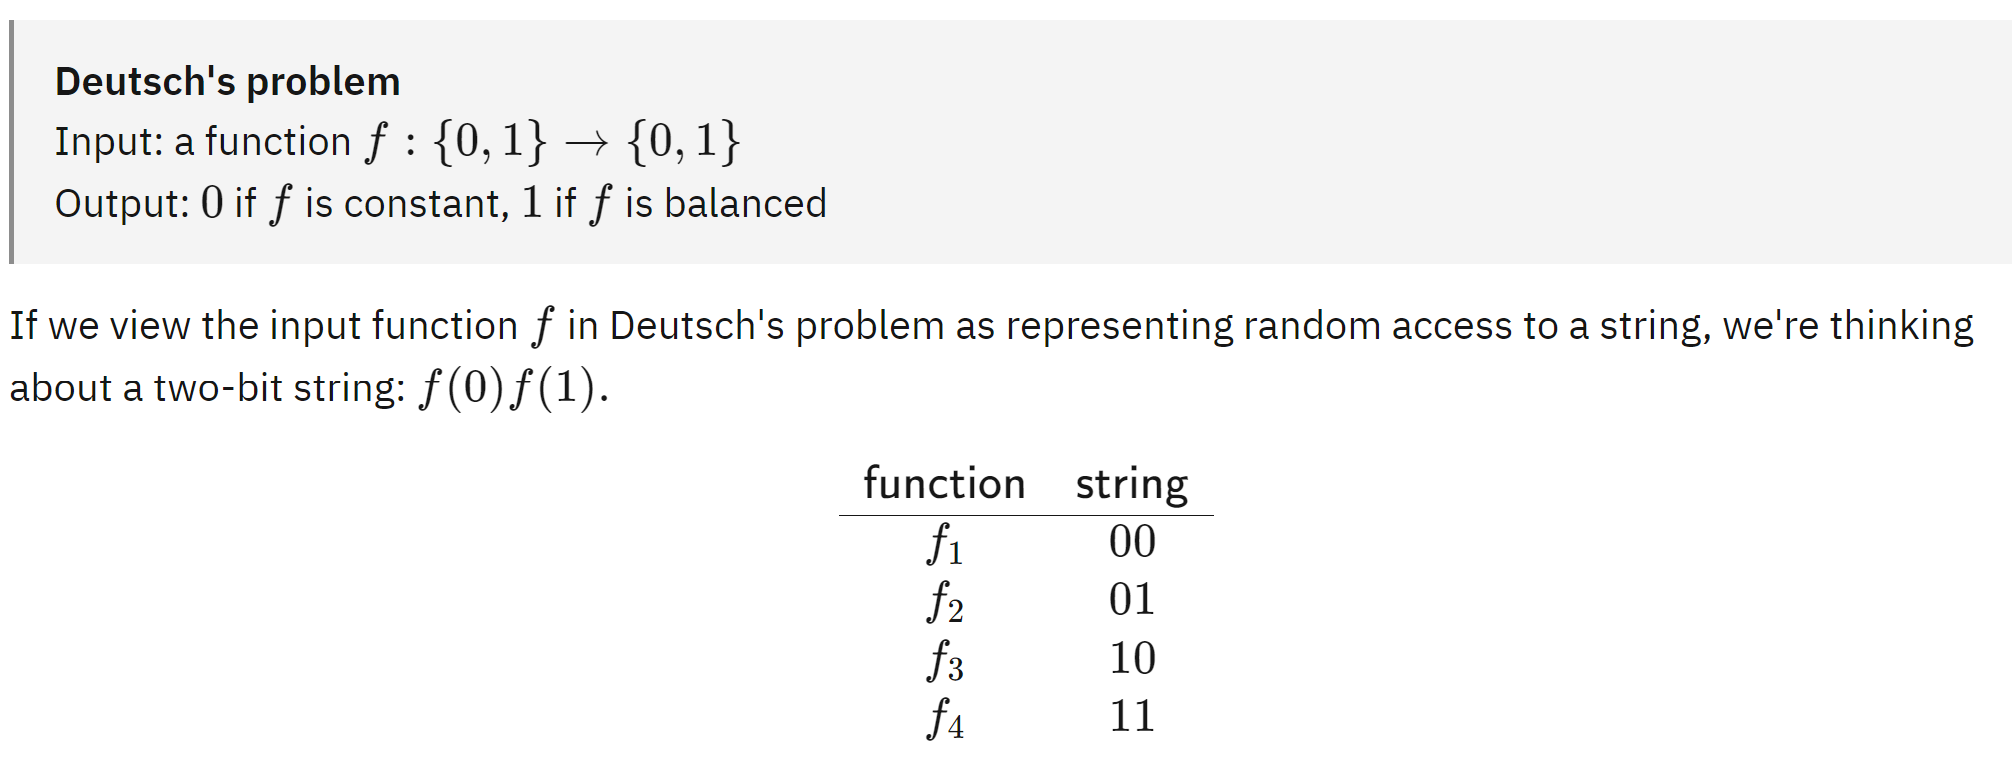

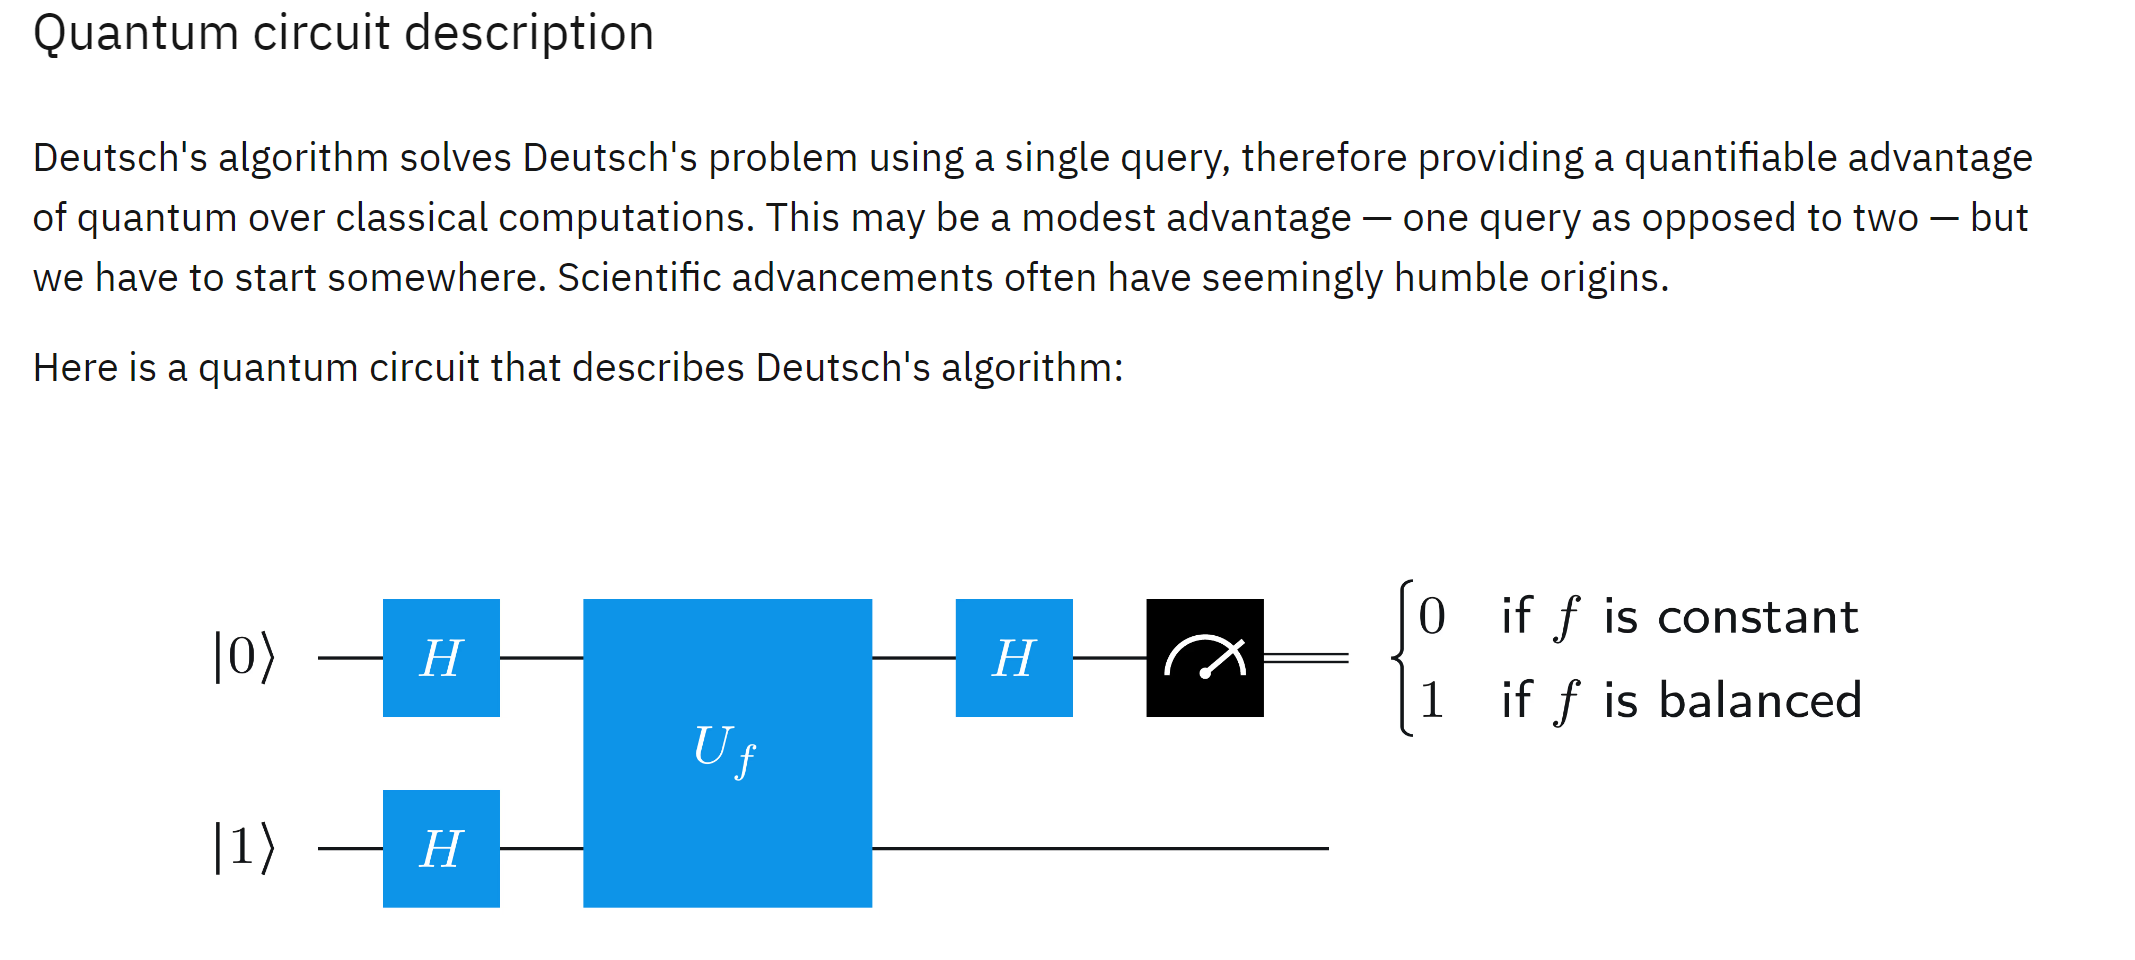

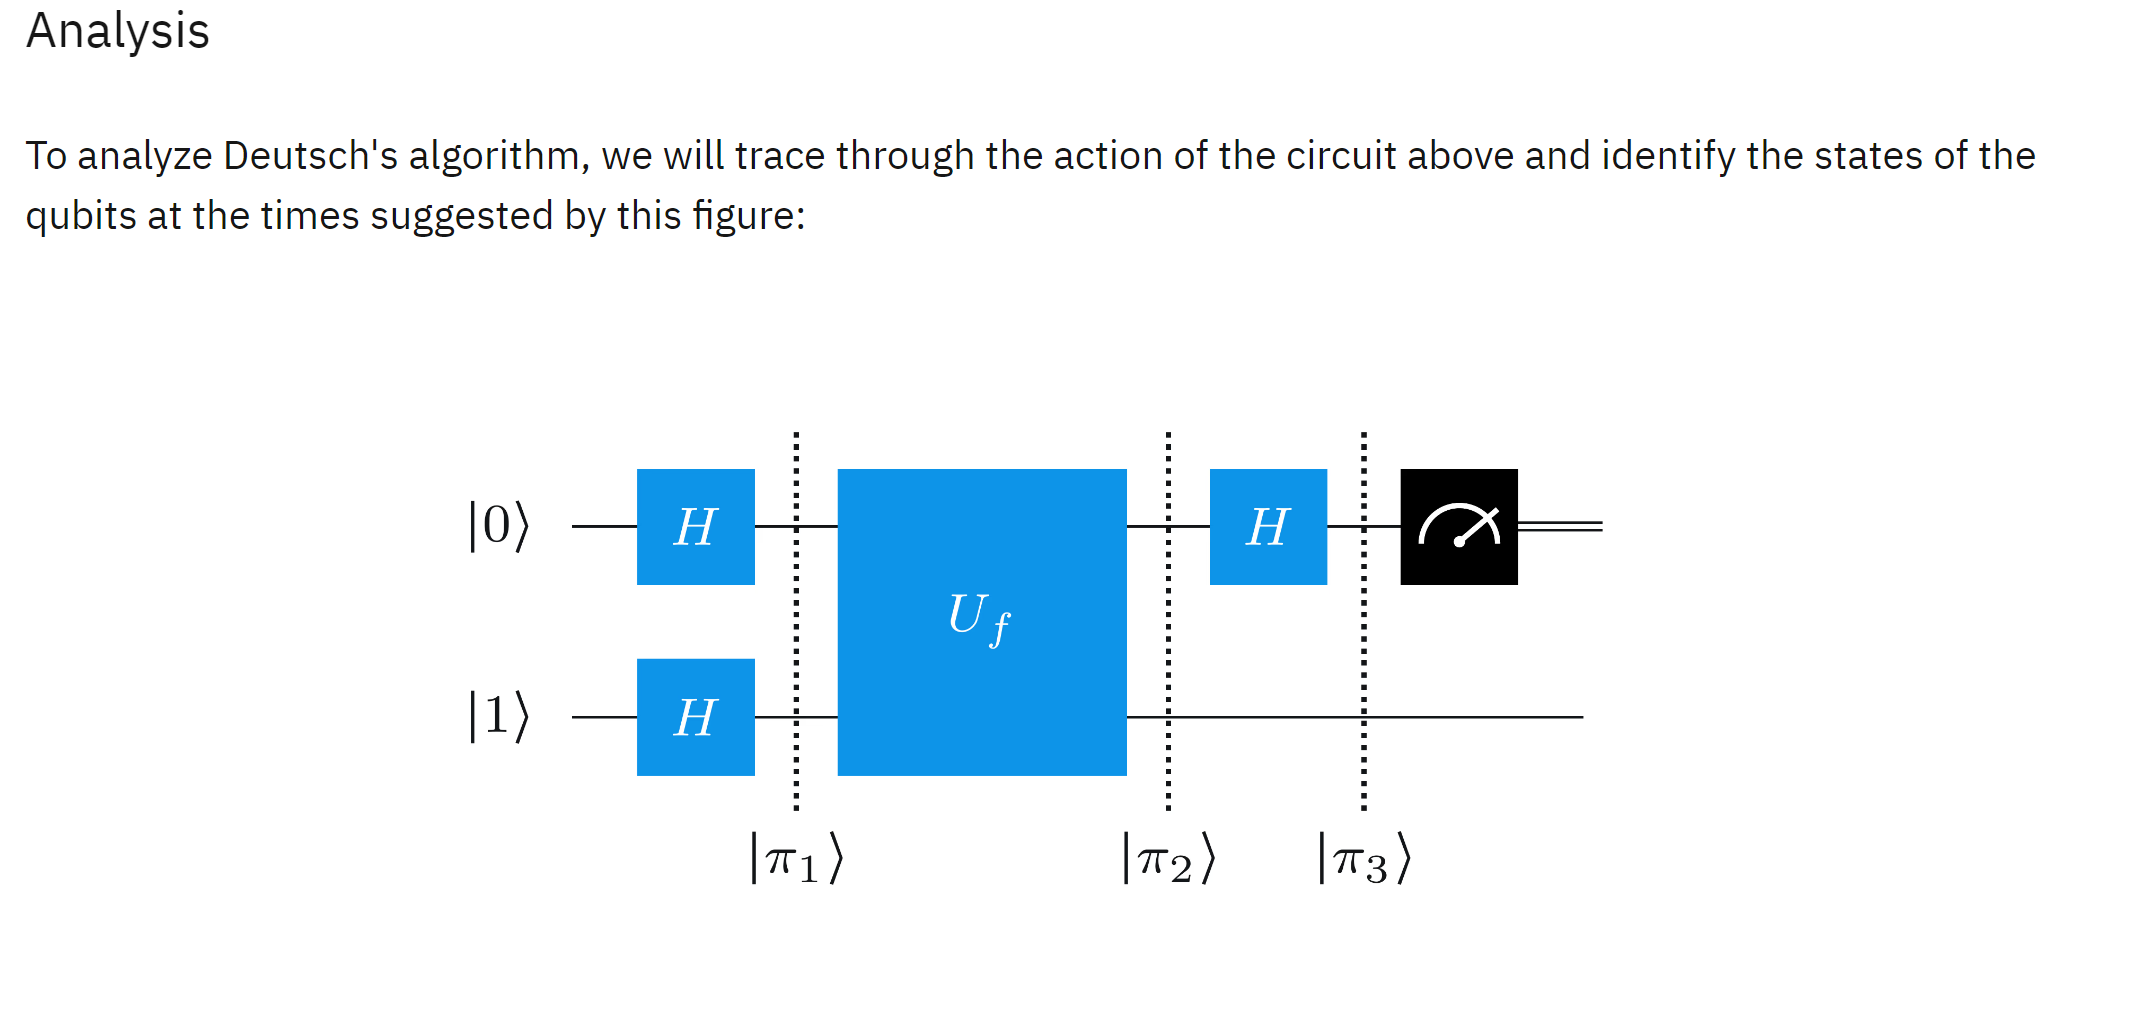

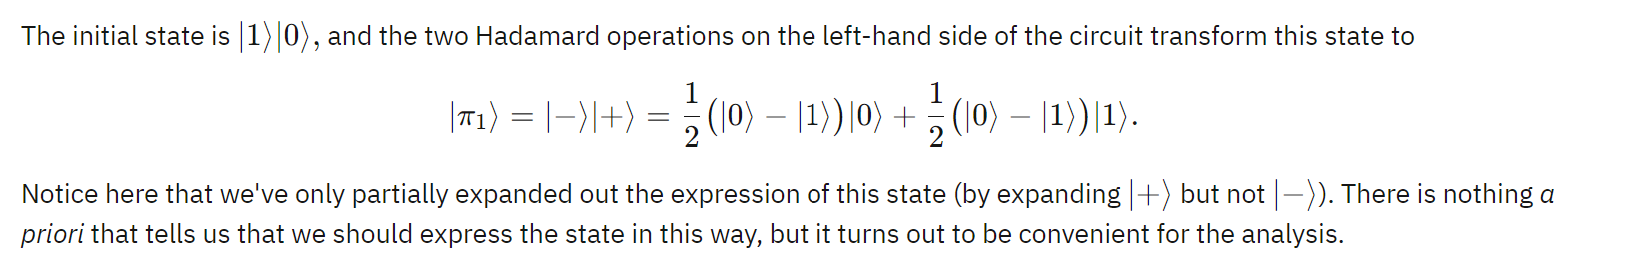

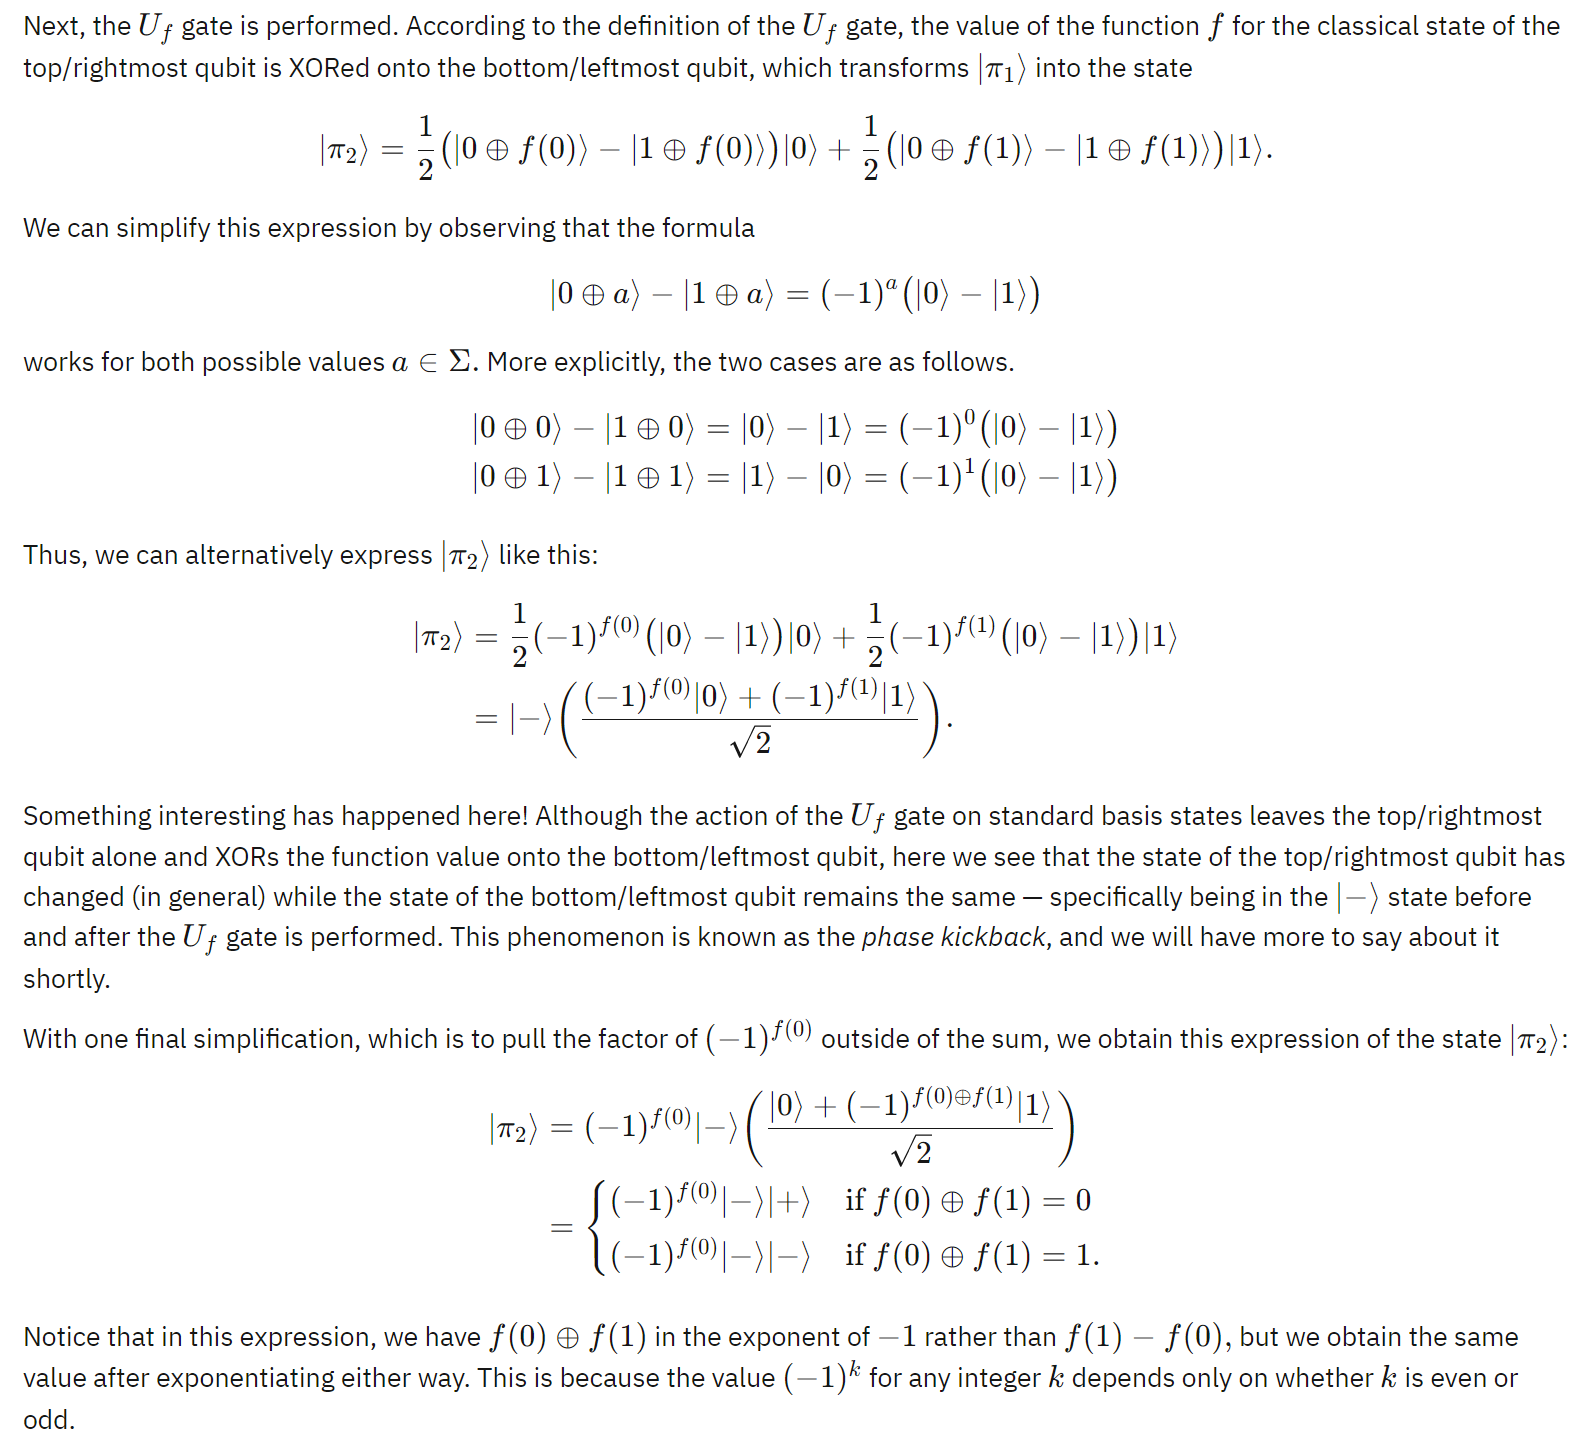

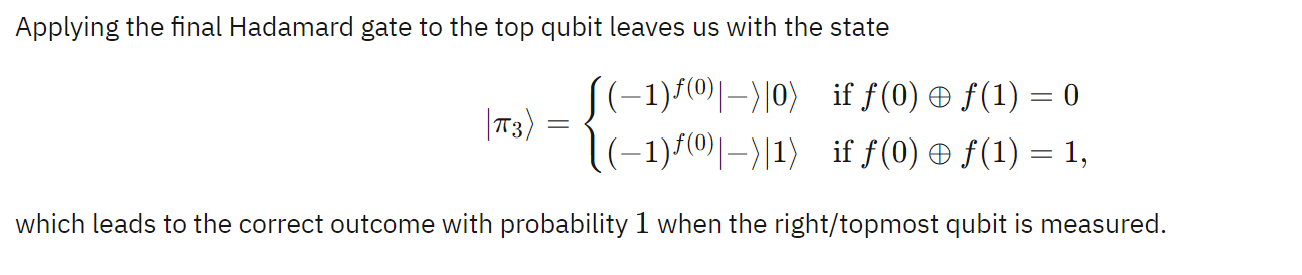

In [ ]:
from qiskit import QuantumCircuit

def deutsch_function(case: int):
    """
    Generate a valid Deutsch function as a `QuantumCircuit`.
    """
    if case not in [1, 2, 3, 4]:
        raise ValueError("`case` must be 1, 2, 3, or 4.")

    f = QuantumCircuit(2)
    if case in [2, 3]:
        f.cx(0, 1)
    if case in [3, 4]:
        f.x(1)
    return f

In [ ]:
#1 -> constant 00
#2 -> balanced 01
#3 -> balanced 10
#4 -> constant 11
for i in range(4):
    print(i+1)
    display(deutsch_function(i+1).draw("mpl"))

In [ ]:
def compile_circuit(function: QuantumCircuit):
    """
    Compiles a circuit for use in Deutsch's algorithm.
    """
    n = function.num_qubits - 1
    qc = QuantumCircuit(n + 1, n)

    qc.x(n)
    qc.h(range(n + 1))

    qc.barrier()
    qc.compose(function, inplace=True)
    qc.barrier()

    qc.h(range(n))
    qc.measure(range(n), range(n))

    return qc

In [ ]:
qcd = compile_circuit(deutsch_function(2))

In [ ]:
display(qcd.draw("mpl"))

In [ ]:
def deutsch_algorithm(function: QuantumCircuit):
    """
    Determine if a Deutsch function is constant or balanced.
    """
    qc = compile_circuit(function)

    counts = run_counts(qc, TARGET, shots=2048)
    # Most frequent measured bitstring (single input qubit for Deutsch).
    outcome = max(counts, key=counts.get)
    if outcome[-1] == "0":
        return "constant"
    return "balanced"

In [ ]:
display(deutsch_algorithm(qcd))

In [ ]:
cc = compile_circuit(deutsch_function(3))
cc.draw("mpl")

In [ ]:
from qiskit.visualization import plot_histogram

In [ ]:
counts = run_counts(cc, TARGET, shots=2048)
print(counts)
plot_histogram(counts)

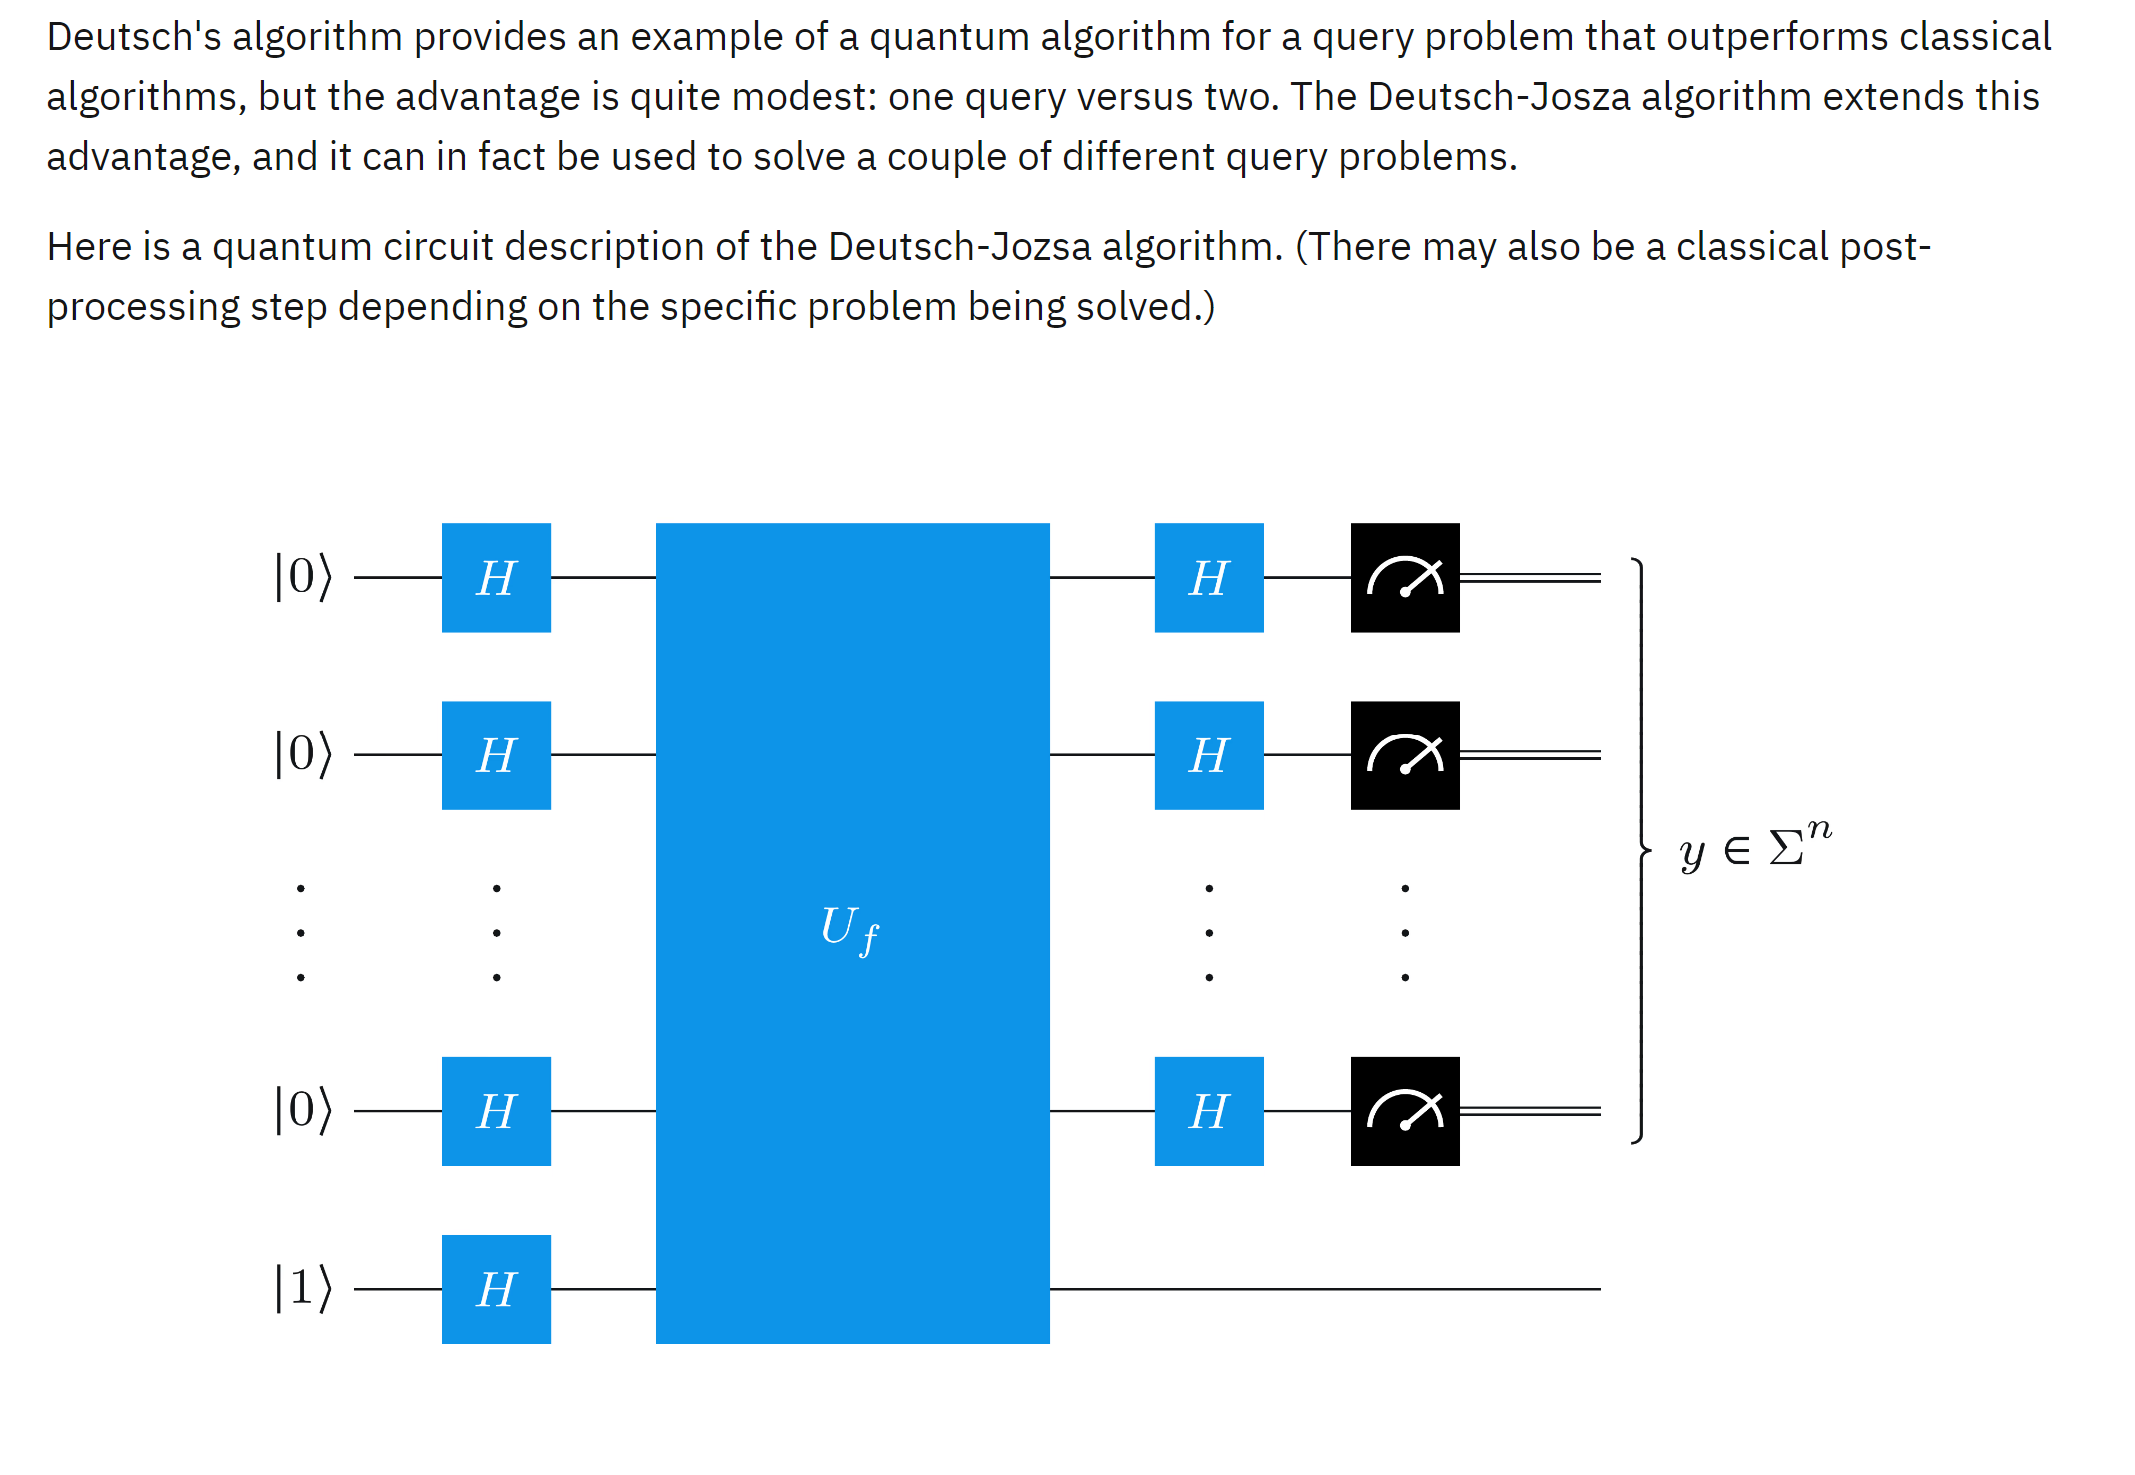

In [ ]:
from qiskit import QuantumCircuit
import numpy as np

def dj_function(num_qubits):
    """
    Create a random Deutsch-Jozsa function.
    """

    qc = QuantumCircuit(num_qubits + 1)
    if np.random.randint(0, 2):
        # Flip output qubit with 50% chance
        qc.x(num_qubits)
    if np.random.randint(0, 2):
        # return constant circuit with 50% chance
        return qc

    # next, choose half the possible input states
    on_states = np.random.choice(
        range(2**num_qubits),  # numbers to sample from
        2**num_qubits // 2,  # number of samples
        replace=False,  # makes sure states are only sampled once
    )

    def add_cx(qc, bit_string):
        for qubit, bit in enumerate(reversed(bit_string)):
            if bit == "1":
                qc.x(qubit)
        return qc

    for state in on_states:
        qc.barrier()  # Barriers are added to help visualize how the functions are created. They can safely be removed.
        qc = add_cx(qc, f"{state:0b}")
        qc.mcx(list(range(num_qubits)), num_qubits)
        qc = add_cx(qc, f"{state:0b}")

    qc.barrier()

    return qc

In [ ]:
dqc = dj_function(3)
display(dqc.draw("mpl"))

In [ ]:
def compile_circuit(function: QuantumCircuit):
    """
    Compiles a circuit for use in the Deutsch-Jozsa algorithm.
    """
    n = function.num_qubits - 1
    qc = QuantumCircuit(n + 1, n)
    qc.x(n)
    qc.h(range(n + 1))
    qc.compose(function, inplace=True)
    qc.h(range(n))
    qc.measure(range(n), range(n))
    return qc

In [ ]:
def dj_algorithm(function: QuantumCircuit):
    """
    Determine if a Deutsch-Jozsa function is constant or balanced.
    """
    qc = compile_circuit(function)

    counts = run_counts(qc, TARGET, shots=2048)
    outcome = max(counts, key=counts.get)
    if "1" in outcome:
        return "balanced"
    return "constant"

In [ ]:
#f = dj_function(5)
#display(f.draw("mpl"))
display(dqc.draw('mpl'))
display(dj_algorithm(dqc))